# Домашнее задание 8. Гравитационная модель и качество прогноза

**Оценивание.** `w8_hw.ipynb` весит 50% оценки. `w8_hw.tex` также весит 50% оценки. Максимальный балл за домашнее задание составляет 10 баллов.
**Пояснение к разбалловке.** В предмете нет официального деления на уровни сложности. Цвета лишь помогают ориентироваться в заданиях. За все пункты синего уровня можно получить максимум 5 баллов из 10. Пункты синего и красного уровней дают максимум 7 баллов из 10. Пункты всех трёх уровней дают максимум 10 баллов из 10. Максимальный балл за домашнее задание составляет 10 баллов. Бонусный пункт 3д даёт 1 дополнительный балл чёрного уровня, но итоговый балл за домашнее задание всё равно не может превышать 10.

В этом блокноте ты выполняешь только техническую часть. Рассчитай постоянные прогнозы, оцени гравитационную модель и её расширения, собери таблицы и построй графики ошибок. Интерпретацию, аргументы и итоговый вывод пиши в `w8_hw.tex`, ссылаясь на результаты этого блокнота.

Ты работаешь с одним товаром команды на уровне HS4 или HS6. Не нужно повторять паспорт товара из домашнего задания 3 и не нужно подгонять выводы под пример с мороженым.

## Для работы тебе пригодятся

Лонгрид недели 8 объясняет ошибку прогноза, MAE, RMSE, функцию потерь, линейную регрессию и $R^2$. Семинар показывает, как сравнивать прогнозы и разбирать ошибки гравитационной модели на примере мороженого. Материалы недели 7 понадобятся для стандартизации и кластеризации рынков.

В этом домашнем задании ты сравнишь гравитационную модель с простыми прогнозами, разберёшь её ошибки и проверишь, помогают ли характеристики импортных рынков. Если будет непонятно, что делать в конкретном блоке, вернись к соответствующему разделу лонгрида и к семинарским ячейкам с похожим расчётом.

В первой кодовой ячейке укажи `PRODUCT_LEVEL` и `PRODUCT_KEY`. В этой работе используй `SAMPLE_SIZE = 30` и `SELECTED_K = 3`. Число кластеров задано заранее, чтобы тестовые годы не участвовали в его выборе. Готовые функции убирают повторяющиеся циклы и оформление таблиц. Последовательность расчётов в каждом пункте напиши самостоятельно.

Торговые потоки, прогнозы, MAE, RMSE и дельты выражай в миллионах долларов. $R^2$ единиц измерения не имеет. Все модели сравнивай на одних и тех же наблюдениях.


In [1]:
# Запусти эту ячейку перед выполнением заданий
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

pd.options.display.float_format = "{:,.3f}".format

OEC_BASE_URL = "https://api-v2.oec.world/tesseract"
TRADE_CUBE = "trade_i_baci_a_17"
WDI_BASE_URL = "https://api.worldbank.org/v2"


def load_oec_data(drilldowns, include=None, measures="Trade Value", limit=50000):
    """Загружает таблицу из OEC/BACI"""
    params = {
        "cube": TRADE_CUBE,
        "drilldowns": ",".join(drilldowns),
        "measures": measures,
        "locale": "en",
        "parents": "false",
        "limit": f"{limit},0",
    }
    if include:
        params["include"] = ";".join(include)
    response = requests.get(
        f"{OEC_BASE_URL}/data.jsonrecords",
        params=params,
        timeout=120,
    )
    response.raise_for_status()
    table = pd.DataFrame(response.json()["data"])
    if table.empty:
        raise ValueError("OEC вернул пустую таблицу. Проверь код товара и уровень HS.")
    return table, response.url


def load_wdi_panel(indicator, value_name, start_year, end_year):
    """Загружает панель показателя World Development Indicators"""
    response = requests.get(
        f"{WDI_BASE_URL}/country/all/indicator/{indicator}",
        params={
            "format": "json",
            "date": f"{start_year}:{end_year}",
            "per_page": 20000,
        },
        timeout=120,
    )
    response.raise_for_status()
    payload = response.json()
    rows = [
        {
            "ISO3": item["countryiso3code"],
            "Year": int(item["date"]),
            value_name: item["value"],
        }
        for item in payload[1]
        if item["countryiso3code"] and item["value"] is not None
    ]
    return pd.DataFrame(rows), response.url


def load_country_coordinates():
    """Загружает координаты столиц и региональную классификацию World Bank"""
    response = requests.get(
        f"{WDI_BASE_URL}/country",
        params={"format": "json", "per_page": 400},
        timeout=120,
    )
    response.raise_for_status()
    rows = [
        {
            "ISO3": item["id"],
            "Страна WDI": item["name"],
            "Регион": item["region"]["value"],
            "Широта": pd.to_numeric(item["latitude"], errors="coerce"),
            "Долгота": pd.to_numeric(item["longitude"], errors="coerce"),
        }
        for item in response.json()[1]
    ]
    return pd.DataFrame(rows), response.url


def great_circle_distance(lat1, lon1, lat2, lon2):
    """Считает расстояние по дуге Земли в километрах"""
    lat1, lon1, lat2, lon2 = map(
        np.radians,
        [lat1, lon1, lat2, lon2],
    )
    value = (
        np.sin((lat2 - lat1) / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    )
    return 6371 * 2 * np.arcsin(np.sqrt(value))


def load_gravity_panel(product_key, product_level="HS4", test_year_count=2):
    """Собирает мировые двусторонние потоки выбранного товара"""
    trade, trade_url = load_oec_data(
        ["Year", "Exporter Country", "Importer Country", product_level],
        [f"{product_level}:{product_key}"],
        limit=100000,
    )
    trade["ISO3 экспортёра"] = (
        trade["Exporter Country ID"].str[-3:].str.upper()
    )
    trade["ISO3 импортёра"] = (
        trade["Importer Country ID"].str[-3:].str.upper()
    )
    trade = (
        trade.groupby(
            [
                "Year",
                "ISO3 экспортёра",
                "Exporter Country",
                "ISO3 импортёра",
                "Importer Country",
            ],
            as_index=False,
        )["Trade Value"]
        .sum()
        .rename(
            columns={
                "Exporter Country": "Экспортёр",
                "Importer Country": "Импортёр",
                "Trade Value": "Торговый поток, долл",
            }
        )
    )

    first_year = int(trade["Year"].min())
    last_year = int(trade["Year"].max())
    gdp, gdp_url = load_wdi_panel(
        "NY.GDP.MKTP.CD", "ВВП, долл", first_year, last_year
    )
    income, income_url = load_wdi_panel(
        "NY.GDP.PCAP.CD", "Доход на душу, долл", first_year, last_year
    )
    coordinates, coordinates_url = load_country_coordinates()

    exporter_gdp = gdp.rename(
        columns={"ISO3": "ISO3 экспортёра", "ВВП, долл": "ВВП экспортёра, долл"}
    )
    importer_gdp = gdp.rename(
        columns={"ISO3": "ISO3 импортёра", "ВВП, долл": "ВВП импортёра, долл"}
    )
    importer_income = income.rename(
        columns={
            "ISO3": "ISO3 импортёра",
            "Доход на душу, долл": "Доход импортёра на душу, долл",
        }
    )
    exporter_coordinates = coordinates[["ISO3", "Широта", "Долгота"]].rename(
        columns={
            "ISO3": "ISO3 экспортёра",
            "Широта": "Широта экспортёра",
            "Долгота": "Долгота экспортёра",
        }
    )
    importer_coordinates = coordinates[["ISO3", "Широта", "Долгота"]].rename(
        columns={
            "ISO3": "ISO3 импортёра",
            "Широта": "Широта импортёра",
            "Долгота": "Долгота импортёра",
        }
    )

    panel = (
        trade.merge(exporter_gdp, on=["Year", "ISO3 экспортёра"], how="inner")
        .merge(importer_gdp, on=["Year", "ISO3 импортёра"], how="inner")
        .merge(importer_income, on=["Year", "ISO3 импортёра"], how="inner")
        .merge(exporter_coordinates, on="ISO3 экспортёра", how="inner")
        .merge(importer_coordinates, on="ISO3 импортёра", how="inner")
    )
    panel["Расстояние, км"] = great_circle_distance(
        panel["Широта экспортёра"],
        panel["Долгота экспортёра"],
        panel["Широта импортёра"],
        panel["Долгота импортёра"],
    )
    panel = panel.loc[
        (panel["Торговый поток, долл"] > 0)
        & (panel["ВВП экспортёра, долл"] > 0)
        & (panel["ВВП импортёра, долл"] > 0)
        & (panel["Доход импортёра на душу, долл"] > 0)
        & (panel["Расстояние, км"] > 0)
        & panel["ISO3 экспортёра"].ne(panel["ISO3 импортёра"])
    ].copy()
    panel["Торговый поток, млн долл"] = panel["Торговый поток, долл"] / 1e6
    panel["Доход импортёра на душу, тыс долл"] = (
        panel["Доход импортёра на душу, долл"] / 1000
    )

    years = sorted(panel["Year"].unique())
    if len(years) <= test_year_count:
        raise ValueError("Недостаточно лет для обучающей и тестовой выборок.")
    test_years = [int(year) for year in years[-test_year_count:]]
    panel = panel.sort_values(
        ["Year", "ISO3 экспортёра", "ISO3 импортёра"]
    ).reset_index(drop=True)

    test_years_text = ", ".join(map(str, test_years))
    note = (
        f"OEC/BACI: {first_year}–{last_year}; "
        f"тестовые годы: {test_years_text}; расстояние между столицами."
    )
    sources = {
        "OEC": trade_url,
        "World Bank GDP": gdp_url,
        "World Bank income": income_url,
        "World Bank coordinates": coordinates_url,
    }
    return panel, test_years, note, sources


def build_market_features(train_data, sample_size=30):
    """Повторяет признаки рынков недели 7 только по обучающему периоду"""
    market_by_year = (
        train_data.groupby(
            ["Year", "ISO3 импортёра", "Импортёр"], as_index=False
        )["Торговый поток, млн долл"]
        .sum()
    )
    years = sorted(market_by_year["Year"].unique())
    first_year, last_year = int(years[0]), int(years[-1])
    span = max(1, last_year - first_year)
    first = (
        market_by_year.loc[
            market_by_year["Year"].eq(first_year),
            ["ISO3 импортёра", "Торговый поток, млн долл"],
        ]
        .rename(columns={"Торговый поток, млн долл": "Первый импорт"})
    )
    last = (
        market_by_year.loc[
            market_by_year["Year"].eq(last_year),
            ["ISO3 импортёра", "Импортёр", "Торговый поток, млн долл"],
        ]
        .rename(columns={"Торговый поток, млн долл": "Импорт товара, млн долл"})
    )
    income = (
        train_data.loc[
            train_data["Year"].eq(last_year),
            ["ISO3 импортёра", "Доход импортёра на душу, тыс долл"],
        ]
        .drop_duplicates("ISO3 импортёра")
    )
    markets = first.merge(last, on="ISO3 импортёра").merge(
        income, on="ISO3 импортёра"
    )
    markets["Рост импорта, %"] = (
        (markets["Импорт товара, млн долл"] / markets["Первый импорт"])
        ** (1 / span)
        - 1
    ) * 100
    markets = markets.nlargest(sample_size, "Импорт товара, млн долл").copy()
    if len(markets) < sample_size:
        raise ValueError("Для кластеризации недостаточно рынков. Уменьши SAMPLE_SIZE.")
    return markets.drop(columns="Первый импорт").sort_values("ISO3 импортёра")


def regression_table(model, feature_names):
    """Возвращает константу и коэффициенты линейной регрессии"""
    return pd.DataFrame(
        {
            "Параметр": ["Константа", *feature_names],
            "Оценка": [model.intercept_, *model.coef_],
        }
    )


def calculate_metrics(actual, predicted):
    """Считает показатели качества для одного набора прогнозов"""
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "R2": r2_score(actual, predicted),
    }


def split_train_test(data, test_years):
    """Разделяет таблицу по заранее выбранным тестовым годам"""
    first_test_year = min(test_years)
    train = data.loc[data["Year"] < first_test_year].copy()
    test = data.loc[data["Year"].isin(test_years)].copy()
    return train, test


def compare_samples(samples):
    """Собирает размеры нескольких выборок в одну таблицу"""
    rows = []
    for name, data in samples.items():
        country_pairs = data[["ISO3 экспортёра", "ISO3 импортёра"]].drop_duplicates()
        rows.append(
            {
                "Выборка": name,
                "Наблюдений": len(data),
                "Экспортёров": data["ISO3 экспортёра"].nunique(),
                "Импортёров": data["ISO3 импортёра"].nunique(),
                "Пар стран": len(country_pairs),
            }
        )
    return pd.DataFrame(rows).set_index("Выборка")


def add_log_columns(data, columns):
    """Добавляет логарифмы положительных столбцов по словарю имён"""
    result = data.copy()
    for source_column, log_column in columns.items():
        if result[source_column].le(0).any():
            raise ValueError(f"В столбце {source_column!r} есть неположительные значения.")
        result[log_column] = np.log(result[source_column])
    return result


def evaluate_forecasts(
    data,
    actual_column,
    forecast_columns,
    include_log_r2=True,
):
    """Сравнивает несколько прогнозов на одной выборке"""
    actual = data[actual_column]
    rows = []
    for model_name, prediction_column in forecast_columns.items():
        predicted = data[prediction_column]
        metrics = calculate_metrics(actual, predicted)
        if include_log_r2:
            metrics["R2 в логарифмах"] = r2_score(
                np.log(actual),
                np.log(predicted),
            )
        rows.append({"Модель": model_name, **metrics})
    return pd.DataFrame(rows).set_index("Модель")


def largest_forecast_errors(
    data,
    actual_column,
    forecast_columns,
    id_columns=("Year", "Экспортёр", "Импортёр"),
):
    """Находит крупнейшую абсолютную ошибку каждого прогноза"""
    rows = []
    for model_name, prediction_column in forecast_columns.items():
        absolute_error = (data[actual_column] - data[prediction_column]).abs()
        row_index = absolute_error.idxmax()
        row = data.loc[row_index, list(id_columns)].to_dict()
        rows.append(
            {
                "Модель": model_name,
                **row,
                "Факт": data.loc[row_index, actual_column],
                "Прогноз": data.loc[row_index, prediction_column],
                "Абсолютная ошибка": absolute_error.loc[row_index],
            }
        )
    return pd.DataFrame(rows)


def prediction_errors(data, actual_column, prediction_column):
    """Добавляет дельту, абсолютную и процентную ошибки прогноза"""
    result = data.copy()
    result["Дельта"] = result[actual_column] - result[prediction_column]
    result["Абсолютная дельта"] = result["Дельта"].abs()
    result["Дельта, % факта"] = 100 * result["Дельта"] / result[actual_column]
    return result.sort_values("Абсолютная дельта", ascending=False)


def plot_largest_deltas(errors, label_columns, n=20):
    """Строит график наблюдений с крупнейшими абсолютными дельтами"""
    plot_data = errors.head(n).sort_values("Дельта").copy()
    labels = plot_data[list(label_columns)].astype(str).agg("–".join, axis=1)
    colors = np.where(plot_data["Дельта"] >= 0, "#6087DC", "#E76F51")
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.barh(labels, plot_data["Дельта"], color=colors)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_xlabel("Факт минус прогноз, млн долл")
    ax.set_ylabel("–".join(label_columns))
    ax.set_title(f"{n} крупнейших абсолютных дельт")
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()


def grouped_prediction_errors(errors, group_columns, n=10):
    """Считает среднюю дельту, MAE и RMSE по группам"""
    result = errors.groupby(group_columns).agg(
        Наблюдений=("Дельта", "size"),
        Средняя_дельта=("Дельта", "mean"),
        MAE=("Абсолютная дельта", "mean"),
        MSE=("Дельта", lambda values: np.mean(values**2)),
    )
    result["RMSE"] = np.sqrt(result.pop("MSE"))
    return result.sort_values("RMSE", ascending=False).head(n)


def attach_group_labels(train, test, lookup, key, group_column):
    """Присоединяет одни и те же метки групп к двум выборкам"""
    labels = lookup[[key, group_column]].drop_duplicates(key)
    train_with_groups = train.merge(
        labels, on=key, how="inner", validate="many_to_one"
    )
    test_with_groups = test.merge(
        labels, on=key, how="inner", validate="many_to_one"
    )
    return train_with_groups, test_with_groups


def aligned_dummies(train_values, test_values, prefix):
    """Создаёт согласованные индикаторы категорий для train и test"""
    train_dummies = pd.get_dummies(
        train_values, prefix=prefix, drop_first=True, dtype=float
    )
    test_dummies = pd.get_dummies(
        test_values, prefix=prefix, drop_first=True, dtype=float
    ).reindex(columns=train_dummies.columns, fill_value=0)
    return train_dummies, test_dummies


def largest_error_comparison(
    data,
    actual_column,
    forecast_columns,
    reference_model,
    n=20,
):
    """Сравнивает модели на наблюдениях, трудных для опорной модели"""
    id_columns = ["Year", "Экспортёр", "Импортёр", actual_column]
    result = data[[*id_columns, *forecast_columns.values()]].copy()
    for model_name, prediction_column in forecast_columns.items():
        result[f"Абсолютная ошибка: {model_name}"] = (
            result[actual_column] - result[prediction_column]
        ).abs()
    return result.nlargest(n, f"Абсолютная ошибка: {reference_model}")


def cluster_markets(markets, feature_columns, n_clusters):
    """Стандартизирует признаки и присваивает рынкам кластеры"""
    result = markets.copy()
    scaler = StandardScaler()
    feature_matrix = scaler.fit_transform(result[feature_columns])
    model = KMeans(n_clusters=n_clusters, n_init=30, random_state=42)
    result["Кластер"] = model.fit_predict(feature_matrix) + 1
    return result, scaler, model


def fit_log_model(train_features, train_target, test_features):
    """Оценивает линейную модель для логарифма и возвращает прогноз в уровнях"""
    model = LinearRegression(fit_intercept=True)
    model.fit(train_features, train_target)
    coefficients = regression_table(model, train_features.columns)
    prediction = np.exp(model.predict(test_features))
    return model, coefficients, prediction


def evaluate_forecasts_by_group(
    data,
    group_column,
    actual_column,
    forecast_columns,
):
    """Сравнивает одни и те же прогнозы внутри нескольких групп"""
    tables = []
    for group, group_data in data.groupby(group_column):
        metrics = evaluate_forecasts(
            group_data,
            actual_column,
            forecast_columns,
        ).reset_index()
        metrics.insert(0, group_column, group)
        tables.append(metrics)
    return pd.concat(tables, ignore_index=True).set_index(
        [group_column, "Модель"]
    )


# Параметры работы: укажи код товара, остальные значения оставь заданными
PRODUCT_LEVEL = "HS6"  # Или HS4
PRODUCT_KEY = "..."
SAMPLE_SIZE = 30
SELECTED_K = 3  # Число групп зафиксировано до проверки на тестовых годах


In [3]:
from pathlib import Path
from datetime import datetime, timezone, timedelta
import json
import hashlib
import os
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import sklearn
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

In [4]:
PRODUCT_LEVEL = 'HS6'
PRODUCT_KEY = '1040900'
PRODUCT_CODE = '040900'
TRADE_CUBE = 'trade_i_baci_a_17'
SAMPLE_SIZE = 30
SELECTED_K = 3
OEC_BASE_URL = 'https://api.oec.world/tesseract'
WDI_BASE_URL = 'https://api.worldbank.org/v2'
ROOT = Path.cwd()
DATA_DIR = ROOT / 'data'
RESULTS_DIR = ROOT / 'results'
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
REFRESH_DATA = False  # False: повторяем расчёт по сохранённым ответам API
source_log = []
pd.options.display.float_format = '{:,.4f}'.format
pd.options.display.max_columns = 12
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})

## Гравитационная модель торговли натуральным мёдом


**Товар:** натуральный мёд, HS2017 040900, уровень HS6. Код товара в OEC: `1040900`

Мы проверяем, насколько ВВП двух стран и расстояние между ними помогают объяснить торговлю мёдом

Сначала сравним модель с прогнозами по среднему и медиане. Затем добавим доход импортёра и группы похожих рынков

Используем мировые двусторонние потоки, а не только российский экспорт и не только Южную Корею

**Доступ к данным:** используем подключение из предыдущей работы: `api.oec.world`

## Источники и проверка загрузки

In [8]:
def fetch_json(base, params=None):
    params = params or {}
    public_url = requests.Request('GET', base, params=params).prepare().url
    cache_key = hashlib.sha256(public_url.encode()).hexdigest()[:24]
    path = DATA_DIR / f'{cache_key}.json'
    meta_path = DATA_DIR / f'{cache_key}.meta.json'
    if path.exists() and meta_path.exists() and not REFRESH_DATA:
        raw = path.read_bytes()
        meta = json.loads(meta_path.read_text(encoding='utf-8'))
        if hashlib.sha256(raw).hexdigest() != meta['SHA256']:
            raise ValueError('Сохранённый ответ изменён. Нужна повторная загрузка.')
        payload = json.loads(raw)
    else:
        response = requests.get(base, params=params, headers={'User-Agent': 'Mozilla/5.0'}, timeout=120)
        if response.status_code in (401, 403):
            raise RuntimeError('Источник не разрешил запрос. Настройте доступ к API; расчёты остановлены.')
        response.raise_for_status()
        payload = response.json()
        raw = json.dumps(payload, ensure_ascii=False).encode('utf-8')
        meta = {'URL': public_url,
                'Дата получения': datetime.now(timezone(timedelta(hours=3))).isoformat(timespec='seconds'),
                'SHA256': hashlib.sha256(raw).hexdigest(), 'Файл': path.name}
        path.write_bytes(raw)
        meta_path.write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding='utf-8')
    source_log.append(meta)
    return payload, public_url


def load_oec_data(drilldowns, include=None, measures='Trade Value', limit=50000):
    params = {'cube': TRADE_CUBE, 'drilldowns': ','.join(drilldowns),
              'measures': measures, 'locale': 'en', 'parents': 'false'}
    if include:
        params['include'] = ';'.join(include)
    frames = []
    offset = 0
    while True:
        payload, url = fetch_json(OEC_BASE_URL + '/data.jsonrecords',
                                  {**params, 'limit': f'{limit},{offset}'})
        frame = pd.DataFrame(payload.get('data', []))
        if frame.empty:
            break
        frames.append(frame)
        if len(frame) < limit:
            break
        offset += limit
        if offset > 2000000:
            raise ValueError('Неожиданно большой ответ. Проверьте фильтр товара и пагинацию.')
    if not frames:
        raise ValueError('Пустой ответ OEC. Проверьте доступ и код товара.')
    result = pd.concat(frames, ignore_index=True)
    expected_total = payload.get('page', {}).get('total')
    if expected_total is not None:
        assert len(result) == int(expected_total), 'Не все строки ответа OEC загружены.'
    if result.duplicated(subset=[c for c in result if c != measures]).any():
        raise ValueError('Повторяющиеся строки OEC. Нужна проверка пагинации.')
    return result, url


def wdi_rows(path, params=None):
    params = {'format': 'json', 'per_page': 20000, **(params or {})}
    payload, url = fetch_json(WDI_BASE_URL + path, params)
    if not isinstance(payload, list) or len(payload) != 2 or payload[1] is None:
        raise ValueError('World Bank вернул неожиданный или пустой ответ.')
    rows = list(payload[1])
    for page in range(2, int(payload[0]['pages']) + 1):
        extra, _ = fetch_json(WDI_BASE_URL + path, {**params, 'page': page})
        rows.extend(extra[1])
    if len(rows) != int(payload[0]['total']):
        raise ValueError('Ответ World Bank загружен не полностью.')
    return rows, url


def load_wdi_panel(indicator, value_name, start_year, end_year):
    rows, url = wdi_rows(f'/country/all/indicator/{indicator}',
                         {'date': f'{start_year}:{end_year}'})
    table = pd.DataFrame([{'ISO3': r['countryiso3code'], 'Year': int(r['date']),
                           value_name: r['value']} for r in rows if r['countryiso3code']])
    assert not table.duplicated(['ISO3', 'Year']).any()
    return table, url


def load_country_coordinates():
    rows, url = wdi_rows('/country')
    table = pd.DataFrame([{'ISO3': r['id'], 'Страна WDI': r['name'],
                          'Регион': r['region']['value'],
                          'Широта': pd.to_numeric(r['latitude'], errors='coerce'),
                          'Долгота': pd.to_numeric(r['longitude'], errors='coerce')}
                         for r in rows if r['region']['id'] != 'NA'])
    assert table['ISO3'].is_unique
    return table, url


def great_circle_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def load_gravity_panel(product_key, product_level='HS6', test_year_count=2):
    global cleaning_audit, excluded_observations, yearly_coverage, completeness_check
    cube, cube_url = fetch_json(OEC_BASE_URL + '/cubes/' + TRADE_CUBE)
    dataset_name = cube.get('annotations', {}).get('dataset_name', '')
    units = next(m.get('annotations', {}).get('units_of_measurement')
                 for m in cube['measures'] if m['name'] == 'Trade Value')
    assert units == 'USD', f'Неожиданные единицы: {units}'
    assert '2017' in dataset_name, 'Проверьте версию HS в метаданных.'
    trade, trade_url = load_oec_data(['Year', 'Exporter Country', 'Importer Country', product_level],
                                    [f'{product_level}:{product_key}'])
    assert trade[product_level + ' ID'].astype(str).eq(product_key).all()
    trade['Year'] = pd.to_numeric(trade['Year'], errors='raise').astype(int)
    trade['Trade Value'] = pd.to_numeric(trade['Trade Value'], errors='raise')
    assert trade['Trade Value'].notna().all() and trade['Trade Value'].ge(0).all()
    trade['ISO3 экспортёра'] = trade['Exporter Country ID'].str[-3:].str.upper()
    trade['ISO3 импортёра'] = trade['Importer Country ID'].str[-3:].str.upper()
    trade = trade.rename(columns={'Exporter Country': 'Экспортёр', 'Importer Country': 'Импортёр',
                                  'Trade Value': 'Торговый поток, долл'})
    keys = ['Year', 'ISO3 экспортёра', 'ISO3 импортёра']
    assert not trade.duplicated(keys).any(), 'Дубликаты пары стран за год.'
    totals, _ = load_oec_data(['Year'], [f'{product_level}:{product_key}'])
    totals['Year'] = totals['Year'].astype(int)
    completeness_check = trade.groupby('Year')['Торговый поток, долл'].sum().to_frame('Сумма пар')
    completeness_check = completeness_check.join(totals.set_index('Year')['Trade Value'].rename('Мировой итог'), how='outer')
    completeness_check['Разность, долл'] = completeness_check['Сумма пар'] - completeness_check['Мировой итог']
    assert completeness_check.notna().all().all()
    assert np.allclose(completeness_check['Сумма пар'], completeness_check['Мировой итог'], rtol=1e-6, atol=1)
    years = sorted(trade['Year'].unique())
    assert len(years) > test_year_count
    test_years = [int(y) for y in years[-test_year_count:]]
    gdp, gdp_url = load_wdi_panel('NY.GDP.MKTP.CD', 'ВВП, долл', min(years), max(years))
    income, income_url = load_wdi_panel('NY.GDP.PCAP.CD', 'Доход на душу, долл', min(years), max(years))
    coords, coords_url = load_country_coordinates()
    panel = trade.copy()
    for side in ['экспортёра', 'импортёра']:
        panel = panel.merge(gdp.rename(columns={'ISO3': f'ISO3 {side}', 'ВВП, долл': f'ВВП {side}, долл'}),
                            on=['Year', f'ISO3 {side}'], how='left', validate='many_to_one')
        panel = panel.merge(coords[['ISO3', 'Широта', 'Долгота']].rename(columns={
            'ISO3': f'ISO3 {side}', 'Широта': f'Широта {side}', 'Долгота': f'Долгота {side}'}),
            on=f'ISO3 {side}', how='left', validate='many_to_one')
    panel = panel.merge(income.rename(columns={'ISO3': 'ISO3 импортёра',
                        'Доход на душу, долл': 'Доход импортёра на душу, долл'}),
                        on=['Year', 'ISO3 импортёра'], how='left', validate='many_to_one')
    panel['Расстояние, км'] = great_circle_distance(panel['Широта экспортёра'], panel['Долгота экспортёра'],
                                                    panel['Широта импортёра'], panel['Долгота импортёра'])
    needed = ['Торговый поток, долл', 'ВВП экспортёра, долл', 'ВВП импортёра, долл',
              'Доход импортёра на душу, долл', 'Расстояние, км']
    valid = np.isfinite(panel[needed]).all(axis=1) & panel[needed].gt(0).all(axis=1)
    valid &= panel['ISO3 экспортёра'].ne(panel['ISO3 импортёра'])
    def reasons(row):
        reasons_list = [c + ': нет данных или неположительное значение' for c in needed
                        if not np.isfinite(row[c]) or row[c] <= 0]
        if row['ISO3 экспортёра'] == row['ISO3 импортёра']:
            reasons_list.append('Совпадают страны')
        return '; '.join(reasons_list)
    excluded_observations = panel.loc[~valid].copy()
    if not excluded_observations.empty:
        excluded_observations['Причина'] = excluded_observations.apply(reasons, axis=1)
    cleaning_audit = pd.DataFrame({'Этап': ['Выгрузка OEC', 'Исключено', 'Для модели'],
        'Строк': [len(panel), int((~valid).sum()), int(valid.sum())],
        'Поток, млн долл': [panel[needed[0]].sum()/1e6, panel.loc[~valid, needed[0]].sum()/1e6,
                            panel.loc[valid, needed[0]].sum()/1e6]})
    raw_yearly = panel.groupby('Year').agg(Строк_до=('Year','size'), Стоимость_до=(needed[0],'sum'))
    panel = panel.loc[valid].copy()
    clean_yearly = panel.groupby('Year').agg(Строк_после=('Year','size'), Стоимость_после=(needed[0],'sum'))
    yearly_coverage = raw_yearly.join(clean_yearly)
    yearly_coverage['Сохранено стоимости, %'] = 100 * yearly_coverage['Стоимость_после']/yearly_coverage['Стоимость_до']
    assert set(panel['Year']) == set(years), 'После очистки потерян целый год. Нельзя молча сдвигать тест.'
    panel['Торговый поток, млн долл'] = panel['Торговый поток, долл']/1e6
    panel['Доход импортёра на душу, тыс долл'] = panel['Доход импортёра на душу, долл']/1000
    panel = panel.sort_values(keys).reset_index(drop=True)
    missing_years = sorted(set(range(min(years), max(years)+1))-set(years))
    note = f'Доступные годы: {years}. Пропущенные годы: {missing_years or "нет"}. Тест: {test_years}.'
    sources = {'OEC': trade_url, 'Метаданные OEC': cube_url, 'ВВП WDI': gdp_url,
               'Доход WDI': income_url, 'Координаты WDI': coords_url}
    return panel, test_years, note, sources


## **[Синий, 2 балла]** Задание 1. Простые прогнозы

### **[Синий, 1 балл]** Пункт 1а. Обучающая и тестовая выборки

Прежде чем строить модель, нужно понять, какой результат она должна превзойти. Представь прогноз, который ничего не знает о странах и назначает один и тот же поток любой паре. Среднее и медиана дадут два таких ориентира. Позже мы проверим, приносит ли гравитационная модель пользу по сравнению с ними.

Загрузи данные вызовом `load_gravity_panel()` и раздели их через `split_train_test()`. Собери размеры выборок с помощью `compare_samples()`. Для торгового потока, ВВП экспортёра, ВВП импортёра и расстояния создай `data_diagnostics` через `describe().T`. Затем рассчитай по `train_data` среднее и медиану и добавь два постоянных прогноза в `test_data`. В `baseline_predictions` оставь год, экспортёра, импортёра, фактический поток и оба прогноза; строки упорядочи по фактическому потоку от большего к меньшему.

Среднее и медиану считай только по обучающей выборке. Тестовые значения не должны участвовать в построении прогноза.

**Что получить на выходе.** `train_data`, `test_data`, `sample_sizes`, `data_diagnostics`, два постоянных прогноза и `baseline_predictions`.


In [9]:
# Загрузи gravity_data и раздели таблицу через split_train_test()
# Создай sample_sizes и data_diagnostics для указанных в задании столбцов
# Рассчитай среднее и медиану по train_data, добавь два прогноза в test_data
# Собери baseline_predictions

gravity_data, test_years, data_note, sources = load_gravity_panel(PRODUCT_KEY, PRODUCT_LEVEL)
train_data, test_data = split_train_test(gravity_data, test_years)
FLOW = 'Торговый поток, млн долл'
KEYS = ['Year', 'ISO3 экспортёра', 'ISO3 импортёра']
sample_sizes = compare_samples({'Все данные': gravity_data, 'Обучение': train_data, 'Тест': test_data})
data_diagnostics = gravity_data[[FLOW, 'ВВП экспортёра, долл', 'ВВП импортёра, долл', 'Расстояние, км']].describe().T
train_mean = train_data[FLOW].mean()
train_median = train_data[FLOW].median()
test_data['Прогноз по среднему'] = train_mean
test_data['Прогноз по медиане'] = train_median
baseline_predictions = test_data[['Year', 'Экспортёр', 'Импортёр', FLOW,
                                  'Прогноз по среднему', 'Прогноз по медиане']].sort_values(FLOW, ascending=False)
print(data_note)
print('Обучающие годы:', sorted(train_data['Year'].unique()))
display(sample_sizes, cleaning_audit, yearly_coverage, completeness_check, data_diagnostics)
print(f'Среднее: {train_mean:.6f}; медиана: {train_median:.6f} млн долл.')
display(baseline_predictions.head(10))
assert train_data['Year'].max() < test_data['Year'].min()
assert train_data['ISO3 экспортёра'].nunique() > 1
assert not gravity_data.duplicated(KEYS).any()
assert len(train_data) + len(test_data) == len(gravity_data)


Доступные годы: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]. Пропущенные годы: нет. Тест: [2023, 2024].
Обучающие годы: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022)]


,Наблюдений,Экспортёров,Импортёров,Пар стран
Выборка,,,,
Все данные,24152,191,200,6438
Обучение,17061,188,199,5734
Тест,7091,173,193,4388


,Этап,Строк,"Поток, млн долл"
0,Выгрузка OEC,25219,"16,421.8815"
1,Исключено,1067,250.0410
2,Для модели,24152,"16,171.8405"


,Строк_до,Стоимость_до,Строк_после,Стоимость_после,"Сохранено стоимости, %"
Year,,,,,
2018,3186,"2,245,399,981.0000",3072,"2,229,548,107.0000",99.2940
2019,3368,"1,991,674,629.0000",3240,"1,970,290,921.0000",98.9263
2020,3523,"2,265,613,199.0000",3390,"2,242,758,502.0000",98.9912
2021,3902,"2,708,917,644.0000",3731,"2,648,764,074.0000",97.7794
2022,3811,"2,739,965,216.0000",3628,"2,684,855,693.0000",97.9887
2023,3778,"2,187,665,458.0000",3614,"2,147,652,283.0000",98.1710
2024,3651,"2,282,645,383.0000",3477,"2,247,970,907.0000",98.4810


,Сумма пар,Мировой итог,"Разность, долл"
Year,,,
2018,"2,245,399,981.0000","2,245,399,981.0000",0.0000
2019,"1,991,674,629.0000","1,991,674,629.0000",0.0000
2020,"2,265,613,199.0000","2,265,613,199.0000",0.0000
2021,"2,708,917,644.0000","2,708,917,644.0000",0.0000
2022,"2,739,965,216.0000","2,739,965,216.0000",0.0000
2023,"2,187,665,458.0000","2,187,665,458.0000",0.0000
2024,"2,282,645,383.0000","2,282,645,383.0000",0.0000


,count,mean,std,min,25%,50%,75%,max
"Торговый поток, млн долл","24,152.0000",0.6696,4.5529,0.0000,0.0004,0.0074,0.1059,210.3126
"ВВП экспортёра, долл","24,152.0000","2,013,377,554,658.8215","4,769,790,861,492.5723","130,995,566.3039","142,022,058,447.2310","473,221,298,968.2160","1,695,627,535,475.8000","29,298,013,000,000.0000"
"ВВП импортёра, долл","24,152.0000","1,621,940,259,417.1943","4,472,297,803,258.4434","50,491,930.9244","47,435,850,422.5352","344,943,149,590.0580","982,661,066,666.6670","29,298,013,000,000.0000"
"Расстояние, км","24,152.0000","5,470.2302","4,325.3278",8.2098,"1,748.3023","4,534.4391","8,347.4465","19,854.7345"


Среднее: 0.690242; медиана: 0.008133 млн долл.


,Year,Экспортёр,Импортёр,"Торговый поток, млн долл",Прогноз по среднему,Прогноз по медиане
18803,2023,India,United States,152.8525,0.6902,0.0081
22298,2024,India,United States,145.6493,0.6902,0.0081
20784,2024,Argentina,United States,126.7388,0.6902,0.0081
17220,2023,Argentina,United States,121.9497,0.6902,0.0081
21183,2024,Brazil,United States,79.1050,0.6902,0.0081
17616,2023,Brazil,United States,67.6115,0.6902,0.0081
21338,2024,China,Japan,59.8702,0.6902,0.0081
23180,2024,New Zealand,United States,59.3694,0.6902,0.0081
17789,2023,China,Japan,54.0129,0.6902,0.0081
19713,2023,New Zealand,United States,49.3880,0.6902,0.0081


### **[Синий, 1 балл]** Пункт 1б. Метрики постоянных прогнозов

Торговые потоки могут быть распределены неравномерно: несколько маршрутов иногда заметно превосходят остальные. Тогда один постоянный прогноз будет чаще ошибаться понемногу, а другой — реже, но намного сильнее. Сопоставление MAE и RMSE покажет, наблюдается ли такое различие для товара твоей команды и как оно влияет на выбор ориентира.

Собери названия двух прогнозов в словарь `BASELINE_FORECASTS`: ключ задаёт название модели в итоговой таблице, а значение — название столбца с прогнозом в `test_data`. Рассчитай `baseline_metrics` через `evaluate_forecasts()`. Через `largest_forecast_errors()` создай `baseline_largest_errors` с одной строкой для каждого прогноза — наблюдением с его наибольшей абсолютной ошибкой.

Сравнивай прогнозы на одной тестовой выборке. Не выбирай лучшее правило до расчёта всех показателей.

**Что получить на выходе.** `baseline_metrics` и `baseline_largest_errors` с годом, экспортёром, импортёром, фактом, прогнозом и абсолютной ошибкой.


In [ ]:
# Создай словарь BASELINE_FORECASTS
# Рассчитай baseline_metrics и baseline_largest_errors готовыми функциями


In [10]:
BASELINE_FORECASTS = {'Среднее': 'Прогноз по среднему', 'Медиана': 'Прогноз по медиане'}
baseline_metrics = evaluate_forecasts(test_data, FLOW, BASELINE_FORECASTS)
baseline_largest_errors = largest_forecast_errors(test_data, FLOW, BASELINE_FORECASTS)
display(baseline_metrics, baseline_largest_errors)
print('Минимальный MAE:', baseline_metrics['MAE'].idxmin())
print('Минимальный RMSE:', baseline_metrics['RMSE'].idxmin())


,MAE,RMSE,R2,R2 в логарифмах
Модель,,,,
Среднее,1.0765,4.4285,-0.0003,-1.7360
Медиана,0.6190,4.4700,-0.0191,-0.0132


,Модель,Year,Экспортёр,Импортёр,Факт,Прогноз,Абсолютная ошибка
0,Среднее,2023,India,United States,152.8525,0.6902,152.1622
1,Медиана,2023,India,United States,152.8525,0.0081,152.8443


Минимальный MAE: Медиана
Минимальный RMSE: Среднее


## **[Синий, 3 балла; Красный, 1 балл]** Задание 2. Классическая гравитационная модель

### **[Синий, 1 балл]** Пункт 2а. Оценивание модели

Постоянный прогноз не различает крупную и небольшую экономику, близкую и далёкую страну. Гравитационная модель вводит эти различия в одну функцию: размер экономик должен поддерживать торговлю, а расстояние — сдерживать её. По оценённым коэффициентам можно проверить, совпадает ли наблюдаемая зависимость с этой логикой.

Добавь логарифмы в обе выборки через `add_log_columns()`. Затем задай три признака `GRAVITY_FEATURES`, создай `gravity_model` и оцени её по `train_data`:

$$
\ln Trade_{ijt}=b_0+b_1\ln GDP_{it}+b_2\ln GDP_{jt}+b_3\ln Distance_{ij}+u_{ijt}.
$$

Используй `LinearRegression(fit_intercept=True)`. Сохрани признаки в `GRAVITY_FEATURES`, модель в `gravity_model`, коэффициенты в `gravity_coefficients` и $R^2$ в логарифмах на обучающей выборке в `train_r2_log`.

На этом шаге не добавляй доход, кластеры и другие признаки. `train_r2_log` описывает подгонку модели на обучающей выборке, но ещё не показывает качество на более поздних наблюдениях.

**Что получить на выходе.** Оценённую модель, таблицу коэффициентов и обучающий $R^2$.


In [11]:
# Добавь логарифмы через add_log_columns()
# Задай GRAVITY_FEATURES и самостоятельно оцени gravity_model
# Сохрани gravity_coefficients и train_r2_log
LOG_COLUMNS = {FLOW: 'ln_trade', 'ВВП экспортёра, долл': 'ln_gdp_exporter',
               'ВВП импортёра, долл': 'ln_gdp_importer', 'Расстояние, км': 'ln_distance'}
train_data = add_log_columns(train_data, LOG_COLUMNS)
test_data = add_log_columns(test_data, LOG_COLUMNS)
GRAVITY_FEATURES = ['ln_gdp_exporter', 'ln_gdp_importer', 'ln_distance']
gravity_model = LinearRegression(fit_intercept=True) #модель обычная линейная регрессия
gravity_model.fit(train_data[GRAVITY_FEATURES], train_data['ln_trade'])
gravity_coefficients = regression_table(gravity_model, GRAVITY_FEATURES)
train_r2_log = r2_score(train_data['ln_trade'], gravity_model.predict(train_data[GRAVITY_FEATURES]))
display(gravity_coefficients)
print(f'R2 в логарифмах на обучении: {train_r2_log:.4f}')


,Параметр,Оценка
0,Константа,-24.9285
1,ln_gdp_exporter,0.5196
2,ln_gdp_importer,0.4988
3,ln_distance,-0.8393


R2 в логарифмах на обучении: 0.1519


### **[Синий, 1 балл]** Пункт 2б. Прогноз на более поздних наблюдениях

Даже подходящее уравнение может хорошо описывать годы, на которых его оценили, и хуже работать позднее. Поэтому теперь важны не коэффициенты сами по себе, а прогноз для наблюдений, которых модель не видела при обучении. Именно на них гравитационную модель можно честно сопоставить с постоянными ориентирами.

Получи прогноз логарифма торгового потока для `test_data`, затем верни его в миллионы долларов с помощью экспоненты. Запиши результат в `Прогноз гравитационной модели`. Модель получает фактические значения ВВП за тестовый год, поэтому это условный прогноз потока на более поздних наблюдениях при известных признаках.

Рассчитай MAE, RMSE и $R^2$ в миллионах долларов, а также $R^2$ в логарифмах. Добавь модель к двум постоянным прогнозам в таблице `model_comparison`.

В этой работе используй простое обратное преобразование через экспоненту. Дополнительную поправку считать не нужно.

**Что получить на выходе.** Прогноз для каждой пары стран, `prediction_table` и `model_comparison` из трёх строк.


In [12]:
# Получи прогноз gravity_model для test_data и примени np.exp()
# Собери ALL_FORECASTS, model_comparison и prediction_table

test_data['Прогноз гравитационной модели'] = np.exp(gravity_model.predict(test_data[GRAVITY_FEATURES]))
ALL_FORECASTS = {**BASELINE_FORECASTS, 'Гравитационная': 'Прогноз гравитационной модели'}
model_comparison = evaluate_forecasts(test_data, FLOW, ALL_FORECASTS)
prediction_table = test_data[['Year', 'Экспортёр', 'Импортёр', FLOW, *ALL_FORECASTS.values()]].sort_values(FLOW, ascending=False)
display(model_comparison, prediction_table.head(10))
print(f'R2 логарифмов: обучение {train_r2_log:.4f}; тест {model_comparison.loc["Гравитационная", "R2 в логарифмах"]:.4f}')

,MAE,RMSE,R2,R2 в логарифмах
Модель,,,,
Среднее,1.0765,4.4285,-0.0003,-1.7360
Медиана,0.6190,4.4700,-0.0191,-0.0132
Гравитационная,0.6138,4.4591,-0.0141,0.1344


,Year,Экспортёр,Импортёр,"Торговый поток, млн долл",Прогноз по среднему,Прогноз по медиане,Прогноз гравитационной модели
18803,2023,India,United States,152.8525,0.6902,0.0081,0.0940
22298,2024,India,United States,145.6493,0.6902,0.0081,0.1001
20784,2024,Argentina,United States,126.7388,0.6902,0.0081,0.0539
17220,2023,Argentina,United States,121.9497,0.6902,0.0081,0.0530
21183,2024,Brazil,United States,79.1050,0.6902,0.0081,0.1221
17616,2023,Brazil,United States,67.6115,0.6902,0.0081,0.1192
21338,2024,China,Japan,59.8702,0.6902,0.0081,0.3767
23180,2024,New Zealand,United States,59.3694,0.6902,0.0081,0.0220
17789,2023,China,Japan,54.0129,0.6902,0.0081,0.3804
19713,2023,New Zealand,United States,49.3880,0.6902,0.0081,0.0212


R2 логарифмов: обучение 0.1519; тест 0.1344


### **[Синий, 1 балл]** Пункт 2в. Дельты по торговым потокам

Одна итоговая метрика сворачивает тысячи прогнозов в одно число и скрывает конкретные маршруты. Дельта возвращает нас от средней оценки к отдельной паре стран. По её знаку видно, недооценила модель поток или, наоборот, ожидала слишком много торговли.

Создай `prediction_deltas` вызовом `prediction_errors()`. Затем передай таблицу и столбцы для подписей в `plot_largest_deltas()`, чтобы построить диаграмму для 20 крупнейших абсолютных дельт. В подписи укажи экспортёра, импортёра и год. Положительная дельта означает, что модель занизила поток, отрицательная — завысила.

Процентную дельту не используй как основной показатель при фактическом потоке, близком к нулю.

**Что получить на выходе.** `prediction_deltas` и график 20 крупнейших промахов.


Дельта = факт минус прогноз. Положительная дельта означает, что модель занизила поток; отрицательная, что завысила

На графике 20 крупнейших ошибок по абсолютной величине. Процентную ошибку не используем для ранжирования: при малом факте она может быть огромной

,Year,Экспортёр,Импортёр,"Торговый поток, млн долл",Прогноз гравитационной модели,Дельта,Абсолютная дельта,"Дельта, % факта"
18803,2023,India,United States,152.8525,0.0940,152.7585,152.7585,99.9385
22298,2024,India,United States,145.6493,0.1001,145.5492,145.5492,99.9313
20784,2024,Argentina,United States,126.7388,0.0539,126.6848,126.6848,99.9574
17220,2023,Argentina,United States,121.9497,0.0530,121.8967,121.8967,99.9565
21183,2024,Brazil,United States,79.1050,0.1221,78.9828,78.9828,99.8456
17616,2023,Brazil,United States,67.6115,0.1192,67.4923,67.4923,99.8238
21338,2024,China,Japan,59.8702,0.3767,59.4935,59.4935,99.3708
23180,2024,New Zealand,United States,59.3694,0.0220,59.3475,59.3475,99.9630
17789,2023,China,Japan,54.0129,0.3804,53.6325,53.6325,99.2957
19713,2023,New Zealand,United States,49.3880,0.0212,49.3668,49.3668,99.9571


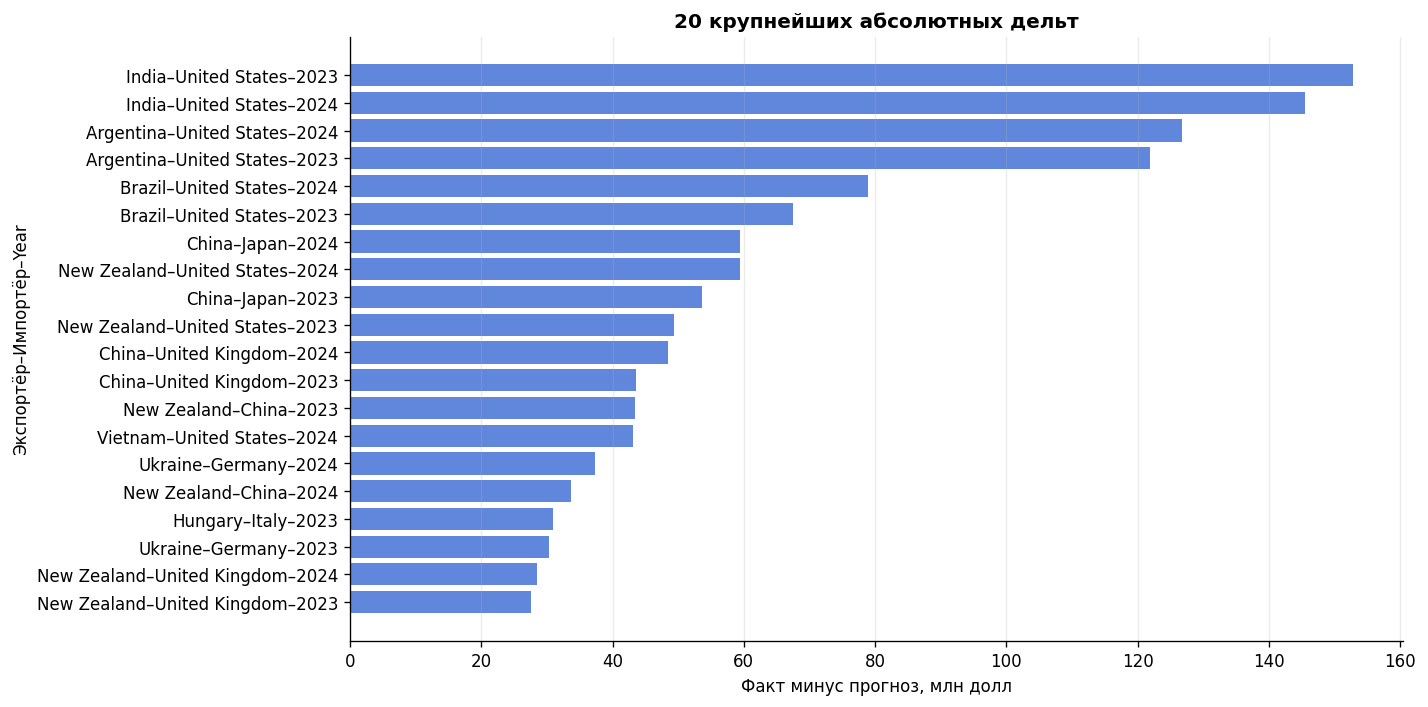

In [13]:
# Создай prediction_deltas через prediction_errors()
# Построй график вызовом plot_largest_deltas()

prediction_deltas = prediction_errors(test_data, FLOW, 'Прогноз гравитационной модели')
display(prediction_deltas[['Year', 'Экспортёр', 'Импортёр', FLOW, 'Прогноз гравитационной модели',
                           'Дельта', 'Абсолютная дельта', 'Дельта, % факта']].head(20))
plot_largest_deltas(prediction_deltas, ['Экспортёр', 'Импортёр', 'Year'], n=20)

### **[Красный, 1 балл]** Пункт 2г. Где сосредоточены ошибки

Если крупные промахи снова и снова связаны с одними импортёрами, общей формуле может не хватать характеристик этих рынков. Сначала нужно обнаружить такое повторение в ошибках. Оно подскажет направление следующей проверки, но ещё не назовёт причину.

Для столбцов `Дельта` и `Абсолютная дельта` создай `delta_diagnostics` через `describe().T`. В `largest_errors` сохрани десять наблюдений с наибольшей абсолютной дельтой. Затем вызови `grouped_prediction_errors()`, сгруппировав строки по коду и названию импортёра, и сохрани результат в `importer_errors`. Функция вернёт десять импортёров с наибольшим RMSE.

Групповая таблица описывает расположение ошибок, но сама по себе не устанавливает их причину.

**Что получить на выходе.** `delta_diagnostics`, `largest_errors` и `importer_errors`.


In [14]:
# Создай delta_diagnostics и выбери largest_errors по абсолютной дельте
# Рассчитай importer_errors через grouped_prediction_errors()

delta_diagnostics = prediction_deltas[['Дельта', 'Абсолютная дельта']].describe().T
largest_errors = prediction_deltas.nlargest(10, 'Абсолютная дельта')
importer_errors = grouped_prediction_errors(prediction_deltas, ['ISO3 импортёра', 'Импортёр'])
display(delta_diagnostics)
display(largest_errors[['Year', 'Экспортёр', 'Импортёр', FLOW, 'Прогноз гравитационной модели', 'Дельта']])
display(importer_errors)

,count,mean,std,min,25%,50%,75%,max
Дельта,"7,091.0000",0.5974,4.4192,-0.4596,-0.0075,-0.0005,0.0680,152.7585
Абсолютная дельта,"7,091.0000",0.6138,4.4170,0.0000,0.0041,0.0147,0.0806,152.7585


,Year,Экспортёр,Импортёр,"Торговый поток, млн долл",Прогноз гравитационной модели,Дельта
18803,2023,India,United States,152.8525,0.0940,152.7585
22298,2024,India,United States,145.6493,0.1001,145.5492
20784,2024,Argentina,United States,126.7388,0.0539,126.6848
17220,2023,Argentina,United States,121.9497,0.0530,121.8967
21183,2024,Brazil,United States,79.1050,0.1221,78.9828
17616,2023,Brazil,United States,67.6115,0.1192,67.4923
21338,2024,China,Japan,59.8702,0.3767,59.4935
23180,2024,New Zealand,United States,59.3694,0.0220,59.3475
17789,2023,China,Japan,54.0129,0.3804,53.6325
19713,2023,New Zealand,United States,49.3880,0.0212,49.3668


,,Наблюдений,Средняя_дельта,MAE,RMSE
ISO3 импортёра,Импортёр,,,,
USA,United States,199,5.8003,5.8245,22.2900
JPN,Japan,122,2.1677,2.1806,8.2831
DEU,Germany,150,3.0151,3.0547,7.1830
GBR,United Kingdom,127,1.7532,1.7982,6.9261
CHN,China,97,1.0086,1.0798,5.6726
ITA,Italy,84,1.7994,1.8205,4.9349
POL,Poland,90,1.1727,1.1904,3.8886
FRA,France,197,1.1185,1.1585,3.8561
AUS,Australia,73,0.9692,0.9757,3.8554


## **[Красный, 1 балл; чёрный, 3 балла + 1 бонусный балл]** Задание 3. Дополнительные признаки

### **[Красный, 1 балл]** Пункт 3а. Кластеры рынков без информации из теста

Разбор ошибок вернул нас к идее прошлой недели: импортные рынки различаются не по одному показателю, а по сочетанию размера, динамики и дохода. Кластеры превратят эти сочетания в несколько типов рынков. Чтобы проверка оставалась честной, будущие для модели годы не должны участвовать в создании этих типов.

Вызови `build_market_features(train_data, SAMPLE_SIZE)`. Полученная таблица повторяет три признака недели 7: импорт товара, рост импорта и доход на душу населения. Все они рассчитаны только по обучающему периоду.

Добавь столбец `Логарифм импорта` по формуле $\ln(1+M)$ с помощью `np.log1p()`. В `CLUSTER_FEATURES` включи логарифм импорта, рост импорта и доход на душу населения. Построй три группы вызовом `cluster_markets()`. В `cluster_profiles` для каждого кластера укажи число стран и средние значения импорта, роста и дохода в исходных единицах. Затем через `attach_group_labels()` создай `extension_train` и `extension_test`. Все модели дальше сравнивай только на этой общей выборке отобранных рынков.

**Что получить на выходе.** `market_features`, `cluster_profiles`, `extension_train` и `extension_test`.


Отбираем 30 крупнейших подходящих рынков по импорту последнего обучающего года.
Как в шаблоне, импорт считаем по потокам, оставшимся после очистки, поэтому он может отличаться от полного импорта OEC

Признаки: ln(1 + импорт), среднегодовой рост импорта и ВВП на душу населения. Перед кластеризацией стандартизируем их

Число групп заранее равно трём. Тестовые годы не участвуют ни в отборе рынков, ни в расчёте признаков, ни в стандартизации

Номера кластеров не являются местами в рейтинге

In [15]:
# Создай market_features, добавь ln(1 + импорт) и задай CLUSTER_FEATURES
# Построй кластеры вызовом cluster_markets() и рассчитай cluster_profiles
# Присоедини группы к train_data и test_data через attach_group_labels()

market_features = build_market_features(train_data, SAMPLE_SIZE)
market_features['Логарифм импорта'] = np.log1p(market_features['Импорт товара, млн долл'])
CLUSTER_FEATURES = ['Логарифм импорта', 'Рост импорта, %', 'Доход импортёра на душу, тыс долл']
market_features, cluster_scaler, market_cluster_model = cluster_markets(market_features, CLUSTER_FEATURES, SELECTED_K)
cluster_profiles = market_features.groupby('Кластер').agg(
    Число_стран=('ISO3 импортёра', 'size'),
    Импорт_млн_долл=('Импорт товара, млн долл', 'mean'),
    Рост_в_год_проц=('Рост импорта, %', 'mean'),
    Доход_тыс_долл=('Доход импортёра на душу, тыс долл', 'mean'),
    Страны=('Импортёр', lambda x: ', '.join(x)))
extension_train, extension_test = attach_group_labels(train_data, test_data, market_features,
                                                      'ISO3 импортёра', 'Кластер')
extension_sample_sizes = compare_samples({'Обучение, 30 рынков': extension_train, 'Тест, 30 рынков': extension_test})
print('Рост импорта рассчитан за годы:', int(train_data['Year'].min()), '-', int(train_data['Year'].max()))
print('Импорт и доход относятся к:', int(train_data['Year'].max()))
display(market_features, cluster_profiles, extension_sample_sizes)


Рост импорта рассчитан за годы: 2018 - 2022
Импорт и доход относятся к: 2022


,ISO3 импортёра,Импортёр,"Импорт товара, млн долл","Доход импортёра на душу, тыс долл","Рост импорта, %",Логарифм импорта,Кластер
5,ARE,United Arab Emirates,39.0113,50.7598,7.3532,3.6892,1
9,AUS,Australia,39.3034,65.1695,-7.3193,3.6964,1
10,AUT,Austria,31.1607,52.3368,-0.8241,3.4707,1
13,BEL,Belgium,98.2853,50.6390,11.4103,4.5980,1
17,BGR,Bulgaria,13.0858,13.9999,37.9466,2.6452,3
30,CAN,Canada,53.2858,56.4969,16.6936,3.9943,1
31,CHE,Switzerland,46.5893,97.8091,4.4396,3.8626,1
33,CHN,China,54.3290,12.9706,-2.3920,4.0133,3
44,CZE,Czechia,26.6140,28.2822,30.0440,3.3183,3
45,DEU,Germany,300.4365,50.5065,-1.0775,5.7086,1


,Число_стран,Импорт_млн_долл,Рост_в_год_проц,Доход_тыс_долл,Страны
Кластер,,,,,
1,20,110.6199,2.8228,57.8383,"United Arab Emirates, Australia, Austria, Belg..."
2,1,13.2105,142.1523,2.8992,Nigeria
3,9,28.4219,11.3138,19.4118,"Bulgaria, China, Czechia, Greece, Indonesia, S..."


,Наблюдений,Экспортёров,Импортёров,Пар стран
Выборка,,,,
"Обучение, 30 рынков",7589,175,30,2243
"Тест, 30 рынков",3190,162,30,1878


### **[Чёрный, 1 балл]** Пункт 3б. Доход импортёра

Первое расширение проверяет, достаточно ли модели знать общий размер экономики импортёра. Доход на душу населения добавляет сведения об условиях рынка, но не измеряет спрос на выбранный товар напрямую. Нас будет интересовать не только знак нового коэффициента, но и то, улучшился ли после его добавления прогноз.

Через `fit_log_model()` повторно оцени классическую модель на общей выборке. Сохрани её как `gravity_common_model`, а прогноз — в столбец `Прогноз классической модели` таблицы `extension_test`. Затем добавь логарифм дохода импортёра, оцени `income_model`, сохрани `income_coefficients` и запиши новый прогноз в столбец `Прогноз модели с доходом`.

Доход на душу населения не равен спросу на выбранный товар. Его коэффициент описывает условную связь внутри модели. Поскольку в модели уже есть общий ВВП импортёра, этот коэффициент нельзя свести к простому сравнению богатых и бедных стран.

**Что получить на выходе.** Две модели, их прогнозы на общей тестовой выборке и `income_coefficients`.


Заново оцениваем классическую модель на общей выборке 30 рынков, к ней добавляем логарифм ВВП на душу населения. Коэффициент дохода читается при неизменном общем ВВП импортёра, поэтому это не простое сравнение богатых и бедных стран

In [16]:
# На общей выборке оцени gravity_common_model через fit_log_model()
# Добавь логарифм дохода импортёра и задай INCOME_FEATURES
# Оцени income_model, сохрани коэффициенты и прогноз
gravity_common_model, gravity_common_coefficients, common_prediction = fit_log_model(
    extension_train[GRAVITY_FEATURES], extension_train['ln_trade'], extension_test[GRAVITY_FEATURES])
extension_test['Прогноз классической модели'] = common_prediction
income_log = {'Доход импортёра на душу, долл': 'ln_income'}
extension_train = add_log_columns(extension_train, income_log)
extension_test = add_log_columns(extension_test, income_log)
INCOME_FEATURES = [*GRAVITY_FEATURES, 'ln_income']
income_model, income_coefficients, income_prediction = fit_log_model(
    extension_train[INCOME_FEATURES], extension_train['ln_trade'], extension_test[INCOME_FEATURES])
extension_test['Прогноз модели с доходом'] = income_prediction
display(gravity_common_coefficients, income_coefficients)

,Параметр,Оценка
0,Константа,-29.5275
1,ln_gdp_exporter,0.7016
2,ln_gdp_importer,0.4950
3,ln_distance,-0.8181


,Параметр,Оценка
0,Константа,-29.8256
1,ln_gdp_exporter,0.7026
2,ln_gdp_importer,0.4941
3,ln_distance,-0.8188
4,ln_income,0.0285


### **[Чёрный, 1 балл]** Пункт 3в. Индикаторы кластеров

Доход описывает только одну сторону рынка, тогда как кластер учитывает сочетание трёх характеристик. Следующая модель проверит, нужен ли разным типам рынков разный исходный уровень прогноза. Реакцию торговли на ВВП и расстояние мы пока оставим одинаковой для всех групп.

Индикатор кластера равен 1 для наблюдений из этого кластера и 0 для остальных. Индикатор первого кластера в модель не добавляется. Поэтому кластер 1 становится группой сравнения, а коэффициенты при остальных индикаторах показывают отличие от него.

Создай согласованные индикаторы через `aligned_dummies()` и добавь их к классическим признакам. Перед объединением сбрось индексы у классических признаков и таблиц индикаторов, чтобы строки совпали. Затем вызови `fit_log_model()`, сохрани `cluster_model`, `cluster_coefficients` и прогноз в `extension_test`.

Индикаторы позволяют постоянной части уравнения для логарифма потока различаться между типами рынков. Коэффициенты при ВВП и расстоянии остаются общими.

**Что получить на выходе.** Матрицы признаков, `cluster_model`, `cluster_coefficients` и новый прогноз.


( группа сравнения: кластер 1. Добавляем индикаторы кластеров 2 и 3. Между группами меняется константа, коэффициенты ВВП и расстояния остаются общими. Модель с кластерами расширяет классическую модель, а не модель с доходом )

In [17]:
# Создай индикаторы кластеров через aligned_dummies()
# Сбрось индексы и собери X_train_cluster и X_test_cluster
# Оцени cluster_model через fit_log_model(), сохрани коэффициенты и прогноз

train_dummies, test_dummies = aligned_dummies(extension_train['Кластер'], extension_test['Кластер'], 'cluster')
X_train_cluster = pd.concat([extension_train[GRAVITY_FEATURES].reset_index(drop=True), train_dummies.reset_index(drop=True)], axis=1)
X_test_cluster = pd.concat([extension_test[GRAVITY_FEATURES].reset_index(drop=True), test_dummies.reset_index(drop=True)], axis=1)
assert list(X_train_cluster) == list(X_test_cluster)
assert X_train_cluster.notna().all().all() and X_test_cluster.notna().all().all()
cluster_model, cluster_coefficients, cluster_prediction = fit_log_model(
    X_train_cluster, extension_train['ln_trade'].reset_index(drop=True), X_test_cluster)
extension_test['Прогноз модели с кластерами'] = cluster_prediction
cluster_effects = cluster_coefficients.loc[cluster_coefficients['Параметр'].str.startswith('cluster_')].copy()
cluster_effects['Отличие прогноза от кластера 1, %'] = 100 * np.expm1(cluster_effects['Оценка'])
display(cluster_coefficients, cluster_effects)


,Параметр,Оценка
0,Константа,-28.6416
1,ln_gdp_exporter,0.7181
2,ln_gdp_importer,0.4550
3,ln_distance,-0.8229
4,cluster_2,-1.4352
5,cluster_3,-0.7003


,Параметр,Оценка,"Отличие прогноза от кластера 1, %"
4,cluster_2,-1.4352,-76.1931
5,cluster_3,-0.7003,-50.3545


### **[Чёрный, 1 балл]** Пункт 3г. Как изменилось качество

Само добавление признака ещё не показывает, что прогноз стал точнее. Об этом можно судить только после сравнения ошибок на тестовой выборке. Общий результат и результаты отдельных типов рынков могут различаться, поэтому расширения нужно проверить сначала на всей общей выборке, а затем внутри каждого кластера.

Собери названия трёх прогнозов в `EXTENSION_FORECASTS` по тому же принципу, что и в пункте 1б. Рассчитай `extension_comparison` через `evaluate_forecasts()` и изменения относительно классической модели в `extension_changes`.

В `extension_changes` рассчитай для каждой метрики разность «расширенная модель минус классическая модель» на общей выборке. Отрицательное изменение MAE или RMSE означает уменьшение ошибки. Положительное изменение $R^2$ означает улучшение по этому показателю.

Через `evaluate_forecasts_by_group()` собери в `cluster_quality` показатели качества каждой модели внутри каждого кластера. Выводы этого пункта относятся только к рынкам, вошедшим в кластеризацию.

**Что получить на выходе.** `extension_comparison`, `extension_changes` и `cluster_quality`.


,MAE,RMSE,R2,R2 в логарифмах
Модель,,,,
Классическая,1.2435,6.6206,-0.0267,0.1480
С доходом,1.2434,6.6202,-0.0266,0.1480
С кластерами,1.2411,6.6157,-0.0252,0.1536


,MAE,RMSE,R2,R2 в логарифмах
Модель,,,,
С доходом,-0.0002,-0.0004,0.0001,0.0000
С кластерами,-0.0025,-0.0049,0.0015,0.0056


MAE   RMSE      R2  R2 в логарифмах  Наблюдений
Кластер Модель                                                         
1       Классическая 1.4376 7.3995 -0.0295           0.1753        2455
        С доходом    1.4375 7.3990 -0.0294           0.1742        2455
        С кластерами 1.4358 7.3933 -0.0278           0.1630        2455
2       Классическая 0.1756 0.5649 -0.0286          -0.1484          50
        С доходом    0.1752 0.5663 -0.0336          -0.1259          50
        С кластерами 0.1725 0.5772 -0.0738           0.0481          50
3       Классическая 0.6259 2.8057 -0.0410           0.0420         685
        С доходом    0.6256 2.8058 -0.0411           0.0452         685
        С кластерами 0.6213 2.8104 -0.0445           0.1065         685

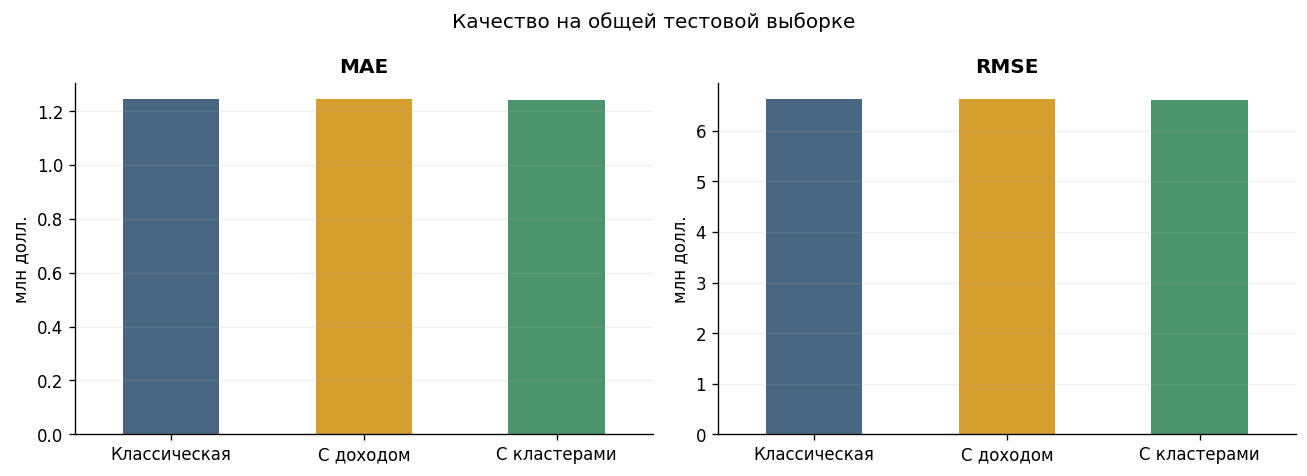

In [18]:
# Собери EXTENSION_FORECASTS и рассчитай extension_comparison
# Найди extension_changes и сравни модели по кластерам в cluster_quality

EXTENSION_FORECASTS = {'Классическая': 'Прогноз классической модели',
                       'С доходом': 'Прогноз модели с доходом',
                       'С кластерами': 'Прогноз модели с кластерами'}
extension_comparison = evaluate_forecasts(extension_test, FLOW, EXTENSION_FORECASTS)
extension_changes = extension_comparison.drop(index='Классическая').subtract(extension_comparison.loc['Классическая'], axis='columns')
cluster_quality = evaluate_forecasts_by_group(extension_test, 'Кластер', FLOW, EXTENSION_FORECASTS)
cluster_counts = extension_test.groupby('Кластер').size().rename('Наблюдений')
cluster_quality = cluster_quality.join(cluster_counts, on='Кластер')
display(extension_comparison, extension_changes, cluster_quality)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ['MAE', 'RMSE']):
    extension_comparison[metric].plot.bar(ax=ax, color=['#486581', '#D69E2E', '#4C956C'], rot=0)
    ax.set(title=metric, ylabel='млн долл.', xlabel='')
    ax.grid(axis='y', alpha=0.2)
fig.suptitle('Качество на общей тестовой выборке')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'model_errors.png', dpi=180, bbox_inches='tight')
plt.show()

### **[Чёрный, 1 бонусный балл]** Пункт 3д. Признаки для следующей проверки

Ошибки модели могут подсказать, каких наблюдаемых характеристик не хватает, но следующий шаг не должен сводиться к ещё одной технической модификации той же формулы. Сформулируй содержательные признаки, которые описывают условия торговли, возможности экспортёра или устройство импортного рынка.

Предложи не менее двух признаков. Хотя бы один должен относиться к паре стран или условиям торговли: например, общий экономический союз, действующее торговое соглашение, тариф, общая граница или логистика. Хотя бы один должен относиться к экспортёру, импортёру или товарной корзине: например, экспорт смежных товаров, импорт товаров-дополнений, климат или структура сбыта.

Для каждого признака укажи уровень наблюдения и год, способ измерения, ожидаемое направление связи, источник данных и риск интерпретации. Признак для тестового года должен строиться только из информации, доступной к моменту прогноза. Ожидаемый знак не считай доказательством причинного эффекта.

Собери предложения в `feature_candidates`, а проверку источников — в `feature_sources`.

**Что получить на выходе.** Не менее двух строк в `feature_candidates`; для использованных источников — организация, название, ссылка, дата обращения, подтверждаемое утверждение и то, чего источник не доказывает.


Предлагаем тариф и выпуск меда в стране экспортера. Это гипотезы для следующего шага, в текущие модели они не включены. Для будущего года можно брать только сведения, опубликованные к моменту прогноза. Даже показатель прошлого года мог быть опубликован позже

In [19]:
feature_candidates = pd.DataFrame([
    {'Признак': 'Применяемый тариф на натуральный мёд',
     'Уровень и год': 'Пара стран, HS6 040900; ставка, известная на дату прогноза года t',
     'Как измерить': 'Адвалорная ставка, %; учитывать преференции. Специфические ставки и квоты проверять отдельно',
     'Ожидаемая связь': 'Более высокий тариф может быть связан с меньшим потоком',
     'Источник данных': 'WTO Tariff & Trade Data, IDB / ADB',
     'Риск интерпретации': 'Связанные и применяемые ставки различаются. Преференция может не использоваться; тариф может отражать защиту рынка'},
    {'Признак': 'Производство натурального мёда в стране экспортёра',
     'Уровень и год': 'Экспортёр; последний год до t с опубликованными на дату прогноза данными',
     'Как измерить': 'ln(1 + выпуск в тоннах); фиксировать год наблюдения и дату публикации',
     'Ожидаемая связь': 'Больший выпуск может быть связан с большими возможностями экспорта',
     'Источник данных': 'FAO, FAOSTAT, Crops and livestock products',
     'Риск интерпретации': 'Часть выпуска потребляется внутри страны. Отличаются качество, цены и реэкспорт; общий фактор может влиять и на выпуск, и на экспорт'}
])
feature_sources = pd.DataFrame([
    {'Организация': 'WTO', 'Название': 'Tariff and trade data',
     'Прямая ссылка': 'https://www.wto.org/english/tratop_e/tariffs_e/tariff_data_e.htm',
     'Дата обращения': '04.11.2026',
     'Какое утверждение подтверждает': 'Есть официальные применяемые и связанные тарифы, а также сведения о преференциальных ставках',
     'Чего источник не доказывает': 'Не доказывает эффект тарифа на мёд и не гарантирует доступность каждой пары стран и года'},
    {'Организация': 'FAO', 'Название': 'Honey and beeswax',
     'Прямая ссылка': 'https://www.fao.org/forestry/nwfp/statistics/honey-and-beeswax/en',
     'Дата обращения': '04.11.2026',
     'Какое утверждение подтверждает': 'FAO публикует сведения о производстве мёда, опираясь прежде всего на FAOSTAT',
     'Чего источник не доказывает': 'Не измеряет доступный для экспорта остаток и не доказывает причинную связь выпуска с торговлей'}
])
display(feature_candidates, feature_sources)


,Признак,Уровень и год,Как измерить,Ожидаемая связь,Источник данных,Риск интерпретации
0,Применяемый тариф на натуральный мёд,"Пара стран, HS6 040900; ставка, известная на д...","Адвалорная ставка, %; учитывать преференции. С...",Более высокий тариф может быть связан с меньши...,"WTO Tariff & Trade Data, IDB / ADB",Связанные и применяемые ставки различаются. Пр...
1,Производство натурального мёда в стране экспор...,Экспортёр; последний год до t с опубликованным...,ln(1 + выпуск в тоннах); фиксировать год наблю...,Больший выпуск может быть связан с большими во...,"FAO, FAOSTAT, Crops and livestock products",Часть выпуска потребляется внутри страны. Отли...


,Организация,Название,Прямая ссылка,Дата обращения,Какое утверждение подтверждает,Чего источник не доказывает
0,WTO,Tariff and trade data,https://www.wto.org/english/tratop_e/tariffs_e...,04.11.2026,Есть официальные применяемые и связанные тариф...,Не доказывает эффект тарифа на мёд и не гарант...
1,FAO,Honey and beeswax,https://www.fao.org/forestry/nwfp/statistics/h...,04.11.2026,"FAO публикует сведения о производстве мёда, оп...",Не измеряет доступный для экспорта остаток и н...


## Проверь себя перед сдачей

- Студенческий блокнот не содержит готовых численных ответов.
- Среднее и медиана рассчитаны только по обучающей выборке.
- Классическая модель оценена для зарегистрированных положительных двусторонних потоков, а не для одного экспортёра.
- Тестовые годы не использованы при оценивании коэффициентов и построении кластеров.
- Все модели внутри каждого сравнения проверены на одинаковых наблюдениях.
- В TeX приведены конкретные числа из таблиц блокнота, и объяснено направление изменения качества.


## Короткие выводы

Мы использовали данные OEC / BACI за 2018-2024 годы. Модель обучалась на 2018-2022 годах и проверялась на 2023-2024 годах

Из 25 219 строк после проверки признаков осталось 24 152. Исключены 1 067 строк, на которые приходится около 1,52% стоимости торговли.
Суммы двусторонних потоков до очистки совпали с мировыми итогами OEC. Причины исключения строк сохранены отдельно

Средний поток в обучении равен 0,6902 млн долларов, а медианный всего 0,0081 млн. Разница показывает, что несколько крупных потоков сильно поднимают среднее.
На тесте медианный прогноз лучше по MAE, а средний по RMSE. То есть результат зависит от того, насколько сильно мы штрафуем крупные ошибки

Знаки коэффициентов классической модели совпали с ожиданиями: при ВВП экспортёра 0,520, при ВВП импортёра 0,499, при расстоянии -0,839
При прочих включённых признаках увеличение расстояния на 1% связано примерно с уменьшением потока на 0,84%. Это связь в данных, а не доказанный эффект расстояния

MAE гравитационной модели равна 0,6138 млн долларов против 0,6190 у медианы. Но её RMSE равна 4,4591 млн против 4,4285 у прогноза по среднему.
Поэтому сказать, что регрессия однозначно лучше простых правил, нельзя. R² в логарифмах на обучении равен 0,1519, на тесте 0,1344; в денежных уровнях тестовый R² отрицательный

Крупнейшие промахи связаны с поставками в США: например, поток Индия - США в 2023 году модель занизила на 152,759 млн долларов.
ВВП и расстояния недостаточно, чтобы точно описать такие крупные поставки. Для объяснения нужны дополнительные данные о производстве и условиях торговли.

В первой группе 20 рынков: в среднем импорт 110,62 млн долларов и ВВП на душу 57,84 тыс. долларов, рост 2,82% в год. Примеры: США, Германия и Япония.
Третья группа объединяет 9 рынков с меньшим средним импортом, 28,42 млн долларов, и более быстрым средним ростом, 11,31% в год. В неё вошли, например, Китай, Южная Корея и Польша

Вторая группа состоит только из Нигерии. Её рост 142,15% в год резко отличается от остальных стран. Это отдельное крайнее наблюдение, а не надёжно установленный тип рынков

Проверка исходной выгрузки показала рост импорта Нигерии с 0,384207 млн долларов в 2018 году до 13,210508 млн в 2022 году. Эти суммы совпадают с очищенной панелью

В 2022 году крупнейшие потоки поступали из Китая, 6,386 млн долларов, и Великобритании, 5,442 млн. Высокий темп связан с низкой начальной базой, но экономическую причину скачка эти данные сами по себе не устанавливают.
Число кластеров оставили равным трём по условию задания. Группу из одной страны интерпретируем осторожно.

На общей выборке 30 рынков добавление дохода изменило MAE с 1,243541 до 1,243365 млн долларов, а RMSE с 6,620579 до 6,620179 млн.
Коэффициент при доходе равен 0,0285: при неизменном общем ВВП импортёра связь с торговлей слабая и положительная. Это не оценка причинного влияния дохода на спрос.
Модель с кластерами дала MAE 1,241052 и RMSE 6,615725 млн долларов. Улучшение небольшое; проверку его статистической значимости мы не проводили

По группам результат различается: у модели с кластерами MAE снижается во всех трёх группах, но RMSE уменьшается только в первой
Во второй и третьей группах RMSE увеличивается. Значит, небольшое общее улучшение не означает, что модель стала точнее для каждого типа рынков

Для следующей проверки предлагаем применяемый тариф на мёд и выпуск мёда у экспортёра. Источники и ограничения указаны в пункте 3д.
По текущим расчётам нельзя выбрать лучший рынок для российского мёда: модель описывает существующие положительные потоки и не учитывает все условия выхода на рынок


# Наши собственные дополнения

## А. Насколько модель подходит для российских поставок

Выделяем из теста только строки с экспортёром RUS. Коэффициенты заново не оцениваем.
Среднее и медиана здесь тоже взяты из мировой обучающей выборки, как в основной работе.
Отдельно показываем США, Германию, Нидерланды, Ирландию, Японию и Южную Корею из третьей домашки.
Отсутствующая строка означает отсутствие наблюдения в очищенной панели, а не доказанный нулевой экспорт.
Дельта = факт минус прогноз. Отрицательная дельта не является оценкой доступного спроса или доказательством перспективности рынка

In [20]:
russia_test = test_data.loc[test_data['ISO3 экспортёра'].eq('RUS')].copy()
assert len(russia_test) > 1
russia_metrics = evaluate_forecasts(russia_test, FLOW, ALL_FORECASTS)
russia_year_metrics = evaluate_forecasts_by_group(russia_test, 'Year', FLOW, ALL_FORECASTS)
russia_deltas = prediction_errors(russia_test, FLOW, 'Прогноз гравитационной модели')
russia_coverage = russia_test.groupby('Year').agg(
    Направлений=('ISO3 импортёра', 'nunique'), Поток_млн_долл=(FLOW, 'sum'))
print('Российский срез теста: наблюдений', len(russia_test),
      '; разных импортёров', russia_test['ISO3 импортёра'].nunique())
display(russia_coverage, russia_metrics, russia_year_metrics)

previous_markets = {'USA': 'США', 'DEU': 'Германия', 'NLD': 'Нидерланды',
                    'IRL': 'Ирландия', 'JPN': 'Япония', 'KOR': 'Южная Корея'}
market_grid = pd.MultiIndex.from_product([test_years, list(previous_markets)],
                  names=['Year', 'ISO3 импортёра']).to_frame(index=False)
russia_selected_markets = market_grid.merge(
    russia_deltas[['Year', 'ISO3 импортёра', FLOW, 'Прогноз гравитационной модели', 'Дельта']],
    on=['Year', 'ISO3 импортёра'], how='left', validate='one_to_one')
russia_selected_markets['Рынок'] = russia_selected_markets['ISO3 импортёра'].map(previous_markets)
russia_selected_markets['Наблюдение'] = np.where(russia_selected_markets[FLOW].notna(),
    'Есть в очищенной панели', 'Нет в очищенной панели; не считаем нулём')
display(russia_selected_markets[['Year', 'Рынок', FLOW, 'Прогноз гравитационной модели', 'Дельта', 'Наблюдение']])
display(russia_deltas[['Year', 'Импортёр', FLOW, 'Прогноз гравитационной модели', 'Дельта']].head(10))
print('На российских строках минимальный MAE:', russia_metrics['MAE'].idxmin(),
      '; минимальный RMSE:', russia_metrics['RMSE'].idxmin())
print('Это проверка мировой модели на существующих поставках России, а не рейтинг новых рынков.')


Российский срез теста: наблюдений 62 ; разных импортёров 37


,Направлений,Поток_млн_долл
Year,,
2023,35,6.0854
2024,27,7.3038


,MAE,RMSE,R2,R2 в логарифмах
Модель,,,,
Среднее,0.5990,0.6389,-1.2275,-1.5747
Медиана,0.2156,0.4759,-0.2357,-0.0159
Гравитационная,0.2207,0.4587,-0.1483,-0.2595


MAE   RMSE      R2  R2 в логарифмах
Year Модель                                               
2023 Среднее        0.5970 0.6362 -1.9305          -1.6654
     Медиана        0.1736 0.4069 -0.1989          -0.0308
     Гравитационная 0.1788 0.3880 -0.0899          -0.2844
2024 Среднее        0.6015 0.6424 -0.7449          -1.4703
     Медиана        0.2700 0.5526 -0.2911          -0.0037
     Гравитационная 0.2750 0.5367 -0.2182          -0.2354

,Year,Рынок,"Торговый поток, млн долл",Прогноз гравитационной модели,Дельта,Наблюдение
0,2023,США,0.3610,0.1021,0.2589,Есть в очищенной панели
1,2023,Германия,0.0024,0.1563,-0.1539,Есть в очищенной панели
2,2023,Нидерланды,0.0003,0.0613,-0.0610,Есть в очищенной панели
3,2023,Ирландия,0.0000,0.0348,-0.0347,Есть в очищенной панели
4,2023,Япония,0.0053,0.0422,-0.0369,Есть в очищенной панели
5,2023,Южная Корея,0.0264,0.0304,-0.0040,Есть в очищенной панели
6,2024,США,0.2019,0.1085,0.0934,Есть в очищенной панели
7,2024,Германия,0.0017,0.1640,-0.1623,Есть в очищенной панели
8,2024,Нидерланды,NaN,NaN,NaN,Нет в очищенной панели; не считаем нулём
9,2024,Ирландия,0.0001,0.0373,-0.0372,Есть в очищенной панели


,Year,Импортёр,"Торговый поток, млн долл",Прогноз гравитационной модели,Дельта
19953,2023,China,2.0261,0.1068,1.9193
23438,2024,Slovakia,1.9471,0.0282,1.9189
23437,2024,Serbia,1.3465,0.0217,1.3248
23422,2024,China,1.2317,0.1120,1.1197
19976,2023,Slovakia,0.7661,0.0265,0.7396
23430,2024,Kazakhstan,0.6685,0.0307,0.6378
19975,2023,Serbia,0.6151,0.0199,0.5952
23442,2024,Uzbekistan,0.5539,0.0167,0.5372
19962,2023,Kazakhstan,0.5054,0.0281,0.4773
23433,2024,Lithuania,0.4014,0.0404,0.3610


На российских строках минимальный MAE: Медиана ; минимальный RMSE: Гравитационная
Это проверка мировой модели на существующих поставках России, а не рейтинг новых рынков.


## Б. Может ли простое повторение прошлого потока быть точнее?

Для каждой пары ищем наблюдение строго за предыдущий календарный год. Если строки нет, прогноз не строим и ноль не подставляем
Для сопоставимости все четыре прогноза проверяем на одном наборе строк. Дополнительно показываем охват, чтобы было видно, сколько наблюдений исключено

**Основная проверка: 2023 год.** Для него поток 2022 года относится к обучающему периоду. Так мы не берём прошлый поток из теста.
**Отдельная последовательная проверка: 2023 и 2024 годы.** Для прогноза 2024 года используем уже наблюдённый поток 2023 года. Это другое условие: ежегодное обновление информации, а не одновременный прогноз двух лет из конца 2022 года.
В обеих проверках регрессия по-прежнему получает фактический ВВП прогнозируемого года. Даты публикации статистики не моделируются, поэтому это не имитация прогноза в реальном времени


In [22]:
previous_flows = gravity_data[KEYS + [FLOW]].copy()
previous_flows['Год прошлого потока'] = previous_flows['Year']
previous_flows['Year'] += 1
previous_flows = previous_flows.rename(columns={FLOW: 'Прогноз по прошлому году'})
history_all = test_data.merge(previous_flows, on=KEYS, how='left', validate='one_to_one')
history_coverage = history_all.groupby('Year').agg(
    Строк_в_тесте=(FLOW, 'size'),
    Строк_с_прошлым_годом=('Прогноз по прошлому году', 'count'),
    Весь_поток_млн_долл=(FLOW, 'sum'))
history_test = history_all.loc[history_all['Прогноз по прошлому году'].notna()].copy()
history_coverage['Поток_с_прошлым_годом_млн_долл'] = history_test.groupby('Year')[FLOW].sum()
history_coverage['Охват строк, %'] = 100 * history_coverage['Строк_с_прошлым_годом']/history_coverage['Строк_в_тесте']
history_coverage['Охват стоимости, %'] = 100 * history_coverage['Поток_с_прошлым_годом_млн_долл']/history_coverage['Весь_поток_млн_долл']
HISTORY_FORECASTS = {**ALL_FORECASTS, 'Прошлый год': 'Прогноз по прошлому году'}
history_first_year = history_test.loc[history_test['Year'].eq(min(test_years))].copy()
history_first_metrics = evaluate_forecasts(history_first_year, FLOW, HISTORY_FORECASTS)
history_rolling_metrics = evaluate_forecasts(history_test, FLOW, HISTORY_FORECASTS)
history_year_metrics = evaluate_forecasts_by_group(history_test, 'Year', FLOW, HISTORY_FORECASTS)
assert (history_test['Year'] - history_test['Год прошлого потока']).eq(1).all()
assert history_first_year['Год прошлого потока'].max() < min(test_years)
assert not history_test.duplicated(KEYS).any()
display(history_coverage)
print('Основная проверка:', min(test_years), '; строк:', len(history_first_year))
display(history_first_metrics)
print('Последовательная проверка двух лет; строк:', len(history_test))
display(history_rolling_metrics, history_year_metrics)
history_gain = 100 * (1 - history_first_metrics.loc['Прошлый год', ['MAE', 'RMSE']] /
                          history_first_metrics.loc['Гравитационная', ['MAE', 'RMSE']])
print('Изменение ошибок при замене регрессии прошлым потоком на основной проверке:')
for metric in ['MAE', 'RMSE']:
    print(f'{metric}: снижение {history_gain[metric]:.2f}% (отрицательное значение означает рост ошибки)')
print('История показывает устойчивость существующих связей, но не помогает оценить рынок без прежних поставок')


,Строк_в_тесте,Строк_с_прошлым_годом,Весь_поток_млн_долл,Поток_с_прошлым_годом_млн_долл,"Охват строк, %","Охват стоимости, %"
Year,,,,,,
2023,3614,2763,"2,147.6523","2,137.3133",76.4527,99.5186
2024,3477,2703,"2,247.9709","2,238.1858",77.7394,99.5647


Основная проверка: 2023 ; строк: 2763


,MAE,RMSE,R2,R2 в логарифмах
Модель,,,,
Среднее,1.1679,4.8999,-0.0003,-1.3390
Медиана,0.7710,4.9587,-0.0244,-0.0190
Гравитационная,0.7638,4.9469,-0.0196,0.1396
Прошлый год,0.3065,1.9028,0.8492,0.7027


Последовательная проверка двух лет; строк: 5466


,MAE,RMSE,R2,R2 в логарифмах
Модель,,,,
Среднее,1.1949,5.0304,-0.0005,-1.3327
Медиана,0.7980,5.0912,-0.0248,-0.0154
Гравитационная,0.7910,5.0788,-0.0198,0.1346
Прошлый год,0.2556,1.5033,0.9106,0.7282


MAE   RMSE      R2  R2 в логарифмах
Year Модель                                               
2023 Среднее        1.1679 4.8999 -0.0003          -1.3390
     Медиана        0.7710 4.9587 -0.0244          -0.0190
     Гравитационная 0.7638 4.9469 -0.0196           0.1396
     Прошлый год    0.3065 1.9028  0.8492           0.7027
2024 Среднее        1.2226 5.1603 -0.0007          -1.3272
     Медиана        0.8257 5.2232 -0.0253          -0.0122
     Гравитационная 0.8189 5.2102 -0.0201           0.1296
     Прошлый год    0.2036 0.9323  0.9673           0.7529

Изменение ошибок при замене регрессии прошлым потоком на основной проверке:
MAE: снижение 59.88% (отрицательное значение означает рост ошибки)
RMSE: снижение 61.54% (отрицательное значение означает рост ошибки)
История показывает устойчивость существующих связей, но не помогает оценить рынок без прежних поставок
